## Thiết lập thư viện và code dự án

# BiLSTM — Vietnamese Word Segmentation

Notebook chạy từ thư mục gốc repository. Cần có `data/processed/train.csv`,
`dev.csv`, `test.csv` và các module trong `src/`.

**Mục tiêu:** kiểm tra định dạng dữ liệu, huấn luyện BiLSTM,
sinh dự đoán trên test và lưu CSV để dùng chung pipeline đánh giá.

In [1]:
import sys
from pathlib import Path

REPOSITORY_ROOT = Path.cwd()
if not (REPOSITORY_ROOT / "src").is_dir():
    REPOSITORY_ROOT = REPOSITORY_ROOT.parent
if not (REPOSITORY_ROOT / "src").is_dir():
    raise RuntimeError("Run this notebook from the repository root or notebooks/ directory")
if str(REPOSITORY_ROOT) not in sys.path:
    sys.path.insert(0, str(REPOSITORY_ROOT))

from IPython.display import Image, display
from src.lstm.config import LSTMConfig
from src.lstm.train import train_pipeline
from src.lstm.predict import WordSegmenterPredictor

## Khởi tạo cấu hình & Huấn luyện mô hình

In [2]:
config = LSTMConfig(
    train_path=REPOSITORY_ROOT / "data/processed/train.csv",
    dev_path=REPOSITORY_ROOT / "data/processed/dev.csv",
    test_path=REPOSITORY_ROOT / "data/processed/test.csv",
    checkpoint_dir=REPOSITORY_ROOT / "checkpoints/lstm",
    output_dir=REPOSITORY_ROOT / "outputs/lstm",
    best_model_path=REPOSITORY_ROOT / "checkpoints/lstm/best_lstm_model.pt",
    vocab_path=REPOSITORY_ROOT / "checkpoints/lstm/vocab.json",
    loss_plot_path=REPOSITORY_ROOT / "outputs/lstm/loss_f1_curve.png",
    epochs=15,
    bidirectional=True,
)
history = train_pipeline(config)

[INFO] Kích thước Vocabulary (từ tập Train): 1,535 âm tiết
Epoch 01/15 | Train Loss: 0.6340 - B-F1: 0.8776 | Dev Loss: 0.4607 - B-F1: 0.9008
Epoch 02/15 | Train Loss: 0.4576 - B-F1: 0.8943 | Dev Loss: 0.4114 - B-F1: 0.9014
Epoch 03/15 | Train Loss: 0.3869 - B-F1: 0.9006 | Dev Loss: 0.3509 - B-F1: 0.9064
Epoch 04/15 | Train Loss: 0.3181 - B-F1: 0.9182 | Dev Loss: 0.2990 - B-F1: 0.9207
Epoch 05/15 | Train Loss: 0.2576 - B-F1: 0.9353 | Dev Loss: 0.2596 - B-F1: 0.9324
Epoch 06/15 | Train Loss: 0.2094 - B-F1: 0.9476 | Dev Loss: 0.2444 - B-F1: 0.9356
Epoch 07/15 | Train Loss: 0.1756 - B-F1: 0.9582 | Dev Loss: 0.2439 - B-F1: 0.9394
Epoch 08/15 | Train Loss: 0.1462 - B-F1: 0.9650 | Dev Loss: 0.2386 - B-F1: 0.9418
Epoch 09/15 | Train Loss: 0.1327 - B-F1: 0.9689 | Dev Loss: 0.2473 - B-F1: 0.9411
Epoch 10/15 | Train Loss: 0.1146 - B-F1: 0.9730 | Dev Loss: 0.2510 - B-F1: 0.9408
Epoch 11/15 | Train Loss: 0.0975 - B-F1: 0.9768 | Dev Loss: 0.2601 - B-F1: 0.9424
Epoch 12/15 | Train Loss: 0.0853 - B-F1

## Hiển thị biểu đồ Loss và Dev F1

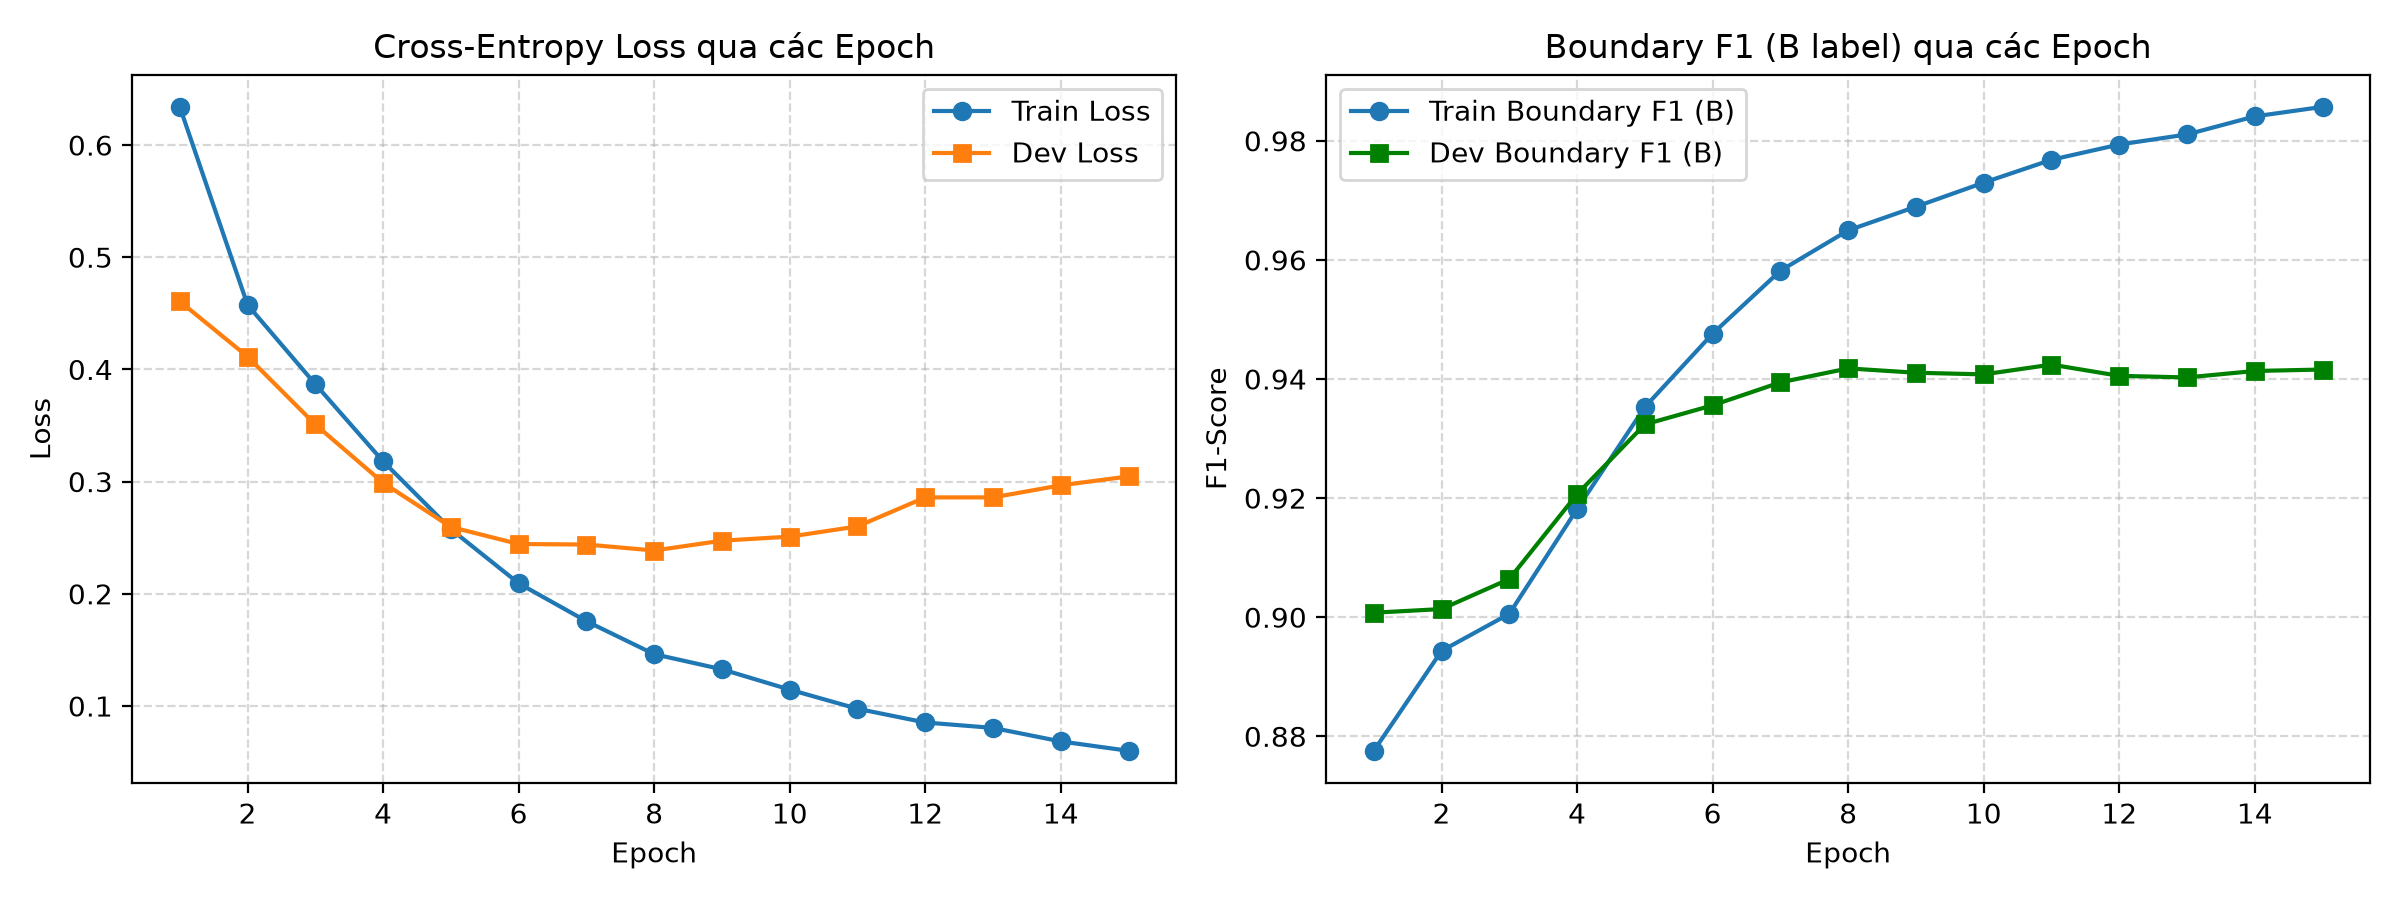

In [3]:
display(Image(filename=str(config.loss_plot_path)))

## Chạy dự đoán trên tập Test & Kiểm tra các ca khó

In [4]:
predictor = WordSegmenterPredictor(config.best_model_path, config.vocab_path)
test_results = predictor.predict_csv(
    config.test_path, REPOSITORY_ROOT / "outputs/lstm/test_predictions.csv"
)
# test_results[["text", "segmented", "pred_segmented", "labels", "pred_labels"]].head(10)
test_results[["text", "labels", "pred_labels"]].head(10)

,text,labels,pred_labels
0,"Thanh bắt chuyện với Hùng và nói : "" Tôi trông...",B B I B B B B B B B B B B I B B B,B B B B B B B B B B B B B B B B B
1,"Hùng giật mình : "" Sao tôi không biết ông nhỉ ...",B B I B B B B B B B B B B B,B B B B B B B B B B B B B B
2,"Thanh quay sang Hùng : "" ông quê đâu nhỉ ?",B B B B B B B B B B B,B B B I B B B B B B B
3,"À , tôi còn có danh sách lớp đây này "" .",B B B B B B I B B B B B,B B B B B B I B B B B B
4,Nói rồi Thanh giở danh sách lớp đọc vanh vách ...,B B B B B I B B B I B I B B I B B I B B B,B B B B B I B B B I B B B B I B B I B B B
5,"Có lẽ vì lịch sự Hùng cũng nói : "" Tôi cũng th...",B I B B I B B B B B B B B B I B B B B B B,B I B B B I B B B B B B B B B B B B B B B
6,"Như dự đoán của Thanh , mấy hôm sau Hùng gặp b...",B B I B B B B B B B B B B B B B,B B I B B B B B B B B B B B I B
7,"Có lẽ đã thấy đủ , bà Loan xách túi đi ra với ...",B I B B B B B B B B B B B B B I B B B,B I B B B B B B B B B B B B B I B B B
8,"Theo chân cửu vạn , chúng tôi đã chứng kiến co...",B B B I B B I B B I B B B I B B B B I B B B B ...,B B B I B B I B B I B B B B B B B B I B B B B ...
9,"Thanh vỗ đùi đánh đét rồi hô váng nhà : "" Thôi...",B B B B B B B B B B B B B B B,B B I B I B B I B B B B B B B
